In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

from collections import Counter
from imblearn.combine import SMOTEENN

from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras import Sequential
from tensorflow.keras.optimizers import Adam

#from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [ ]:
career = pd.read_csv('/content/Career_Switch_Prediction_Dataset.csv')

career.head(10)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,will_change_career
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,0,83,0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,0,52,1
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0
5,21651,city_176,0.764,NaN,Has relevent experience,Part time course,Graduate,STEM,11,NaN,NaN,1,24,1
6,28806,city_160,0.920,Male,Has relevent experience,no_enrollment,High School,NaN,5,50-99,Funded Startup,1,24,0
7,402,city_46,0.762,Male,Has relevent experience,no_enrollment,Graduate,STEM,13,<10,Pvt Ltd,>4,18,1
8,27107,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,46,1
9,699,city_103,0.920,NaN,Has relevent experience,no_enrollment,Graduate,STEM,17,10000+,Pvt Ltd,>4,123,0


In [ ]:
k=career.shape
print(f'Shape of the dataset is {k}. The dataset has {k[0]} rows and {k[1]} columns.')

Shape of the dataset is (5000, 14). The dataset has 5000 rows and 14 columns.


DATA EXTRAPOLATION

In [ ]:
numerical_data = career.select_dtypes(include='number')

numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 4 numerical features: 

['enrollee_id', 'city_development_index', 'training_hours', 'will_change_career']


In [ ]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
enrollee_id,5000.0,17022.88300,9656.969716,7.000,8736.500,17068.000,25389.25,33380.000
city_development_index,5000.0,0.82941,0.122429,0.448,0.743,0.903,0.92,0.949
training_hours,5000.0,65.02720,59.946693,1.000,23.000,47.000,88.00,336.000
will_change_career,5000.0,0.25240,0.434433,0.000,0.000,0.000,1.00,1.000


In [ ]:
categorical_data=career.select_dtypes(include= 'object')

categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 10 categorical features: 

['city', 'gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']


In [ ]:
categorical_data.describe().T

,count,unique,top,freq
city,5000,113,city_103,1163
gender,3887,3,Male,3507
relevent_experience,5000,2,Has relevent experience,3598
enrolled_university,4893,3,no_enrollment,3571
education_level,4882,5,Graduate,3037
major_discipline,4276,6,STEM,3786
experience,4989,22,>20,859
company_size,3429,8,50-99,813
company_type,3379,6,Pvt Ltd,2550
last_new_job,4896,6,1,2094


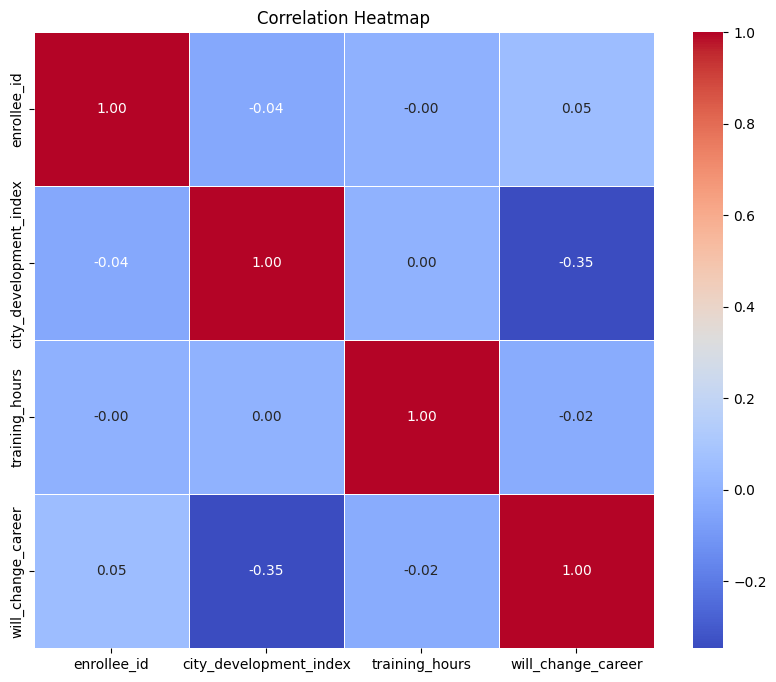

In [ ]:
corr_matrix = numerical_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
numerical_data.var()

,0
enrollee_id,9.325706e+07
city_development_index,1.498895e-02
training_hours,3.593606e+03
will_change_career,1.887320e-01


In [ ]:
numerical_data.skew()

,0
enrollee_id,-0.022808
city_development_index,-1.013328
training_hours,1.853677
will_change_career,1.140333


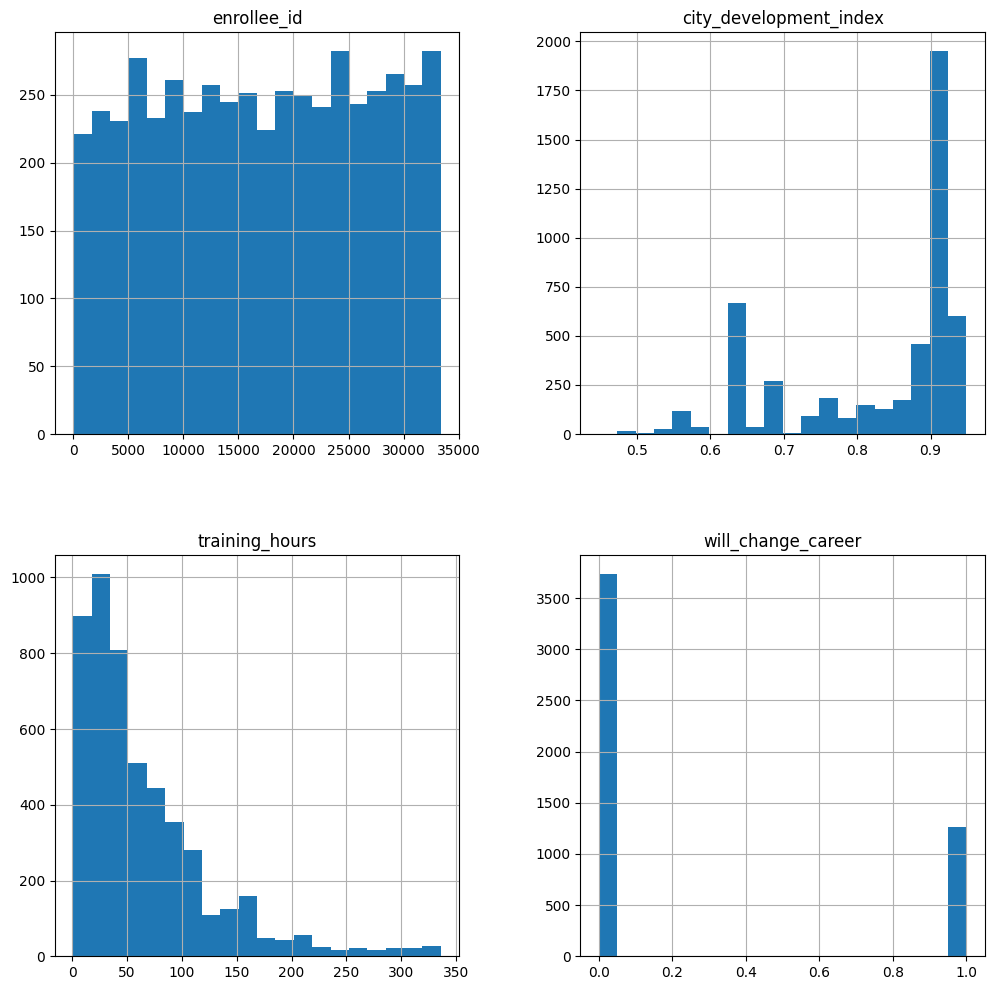

In [ ]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.show()

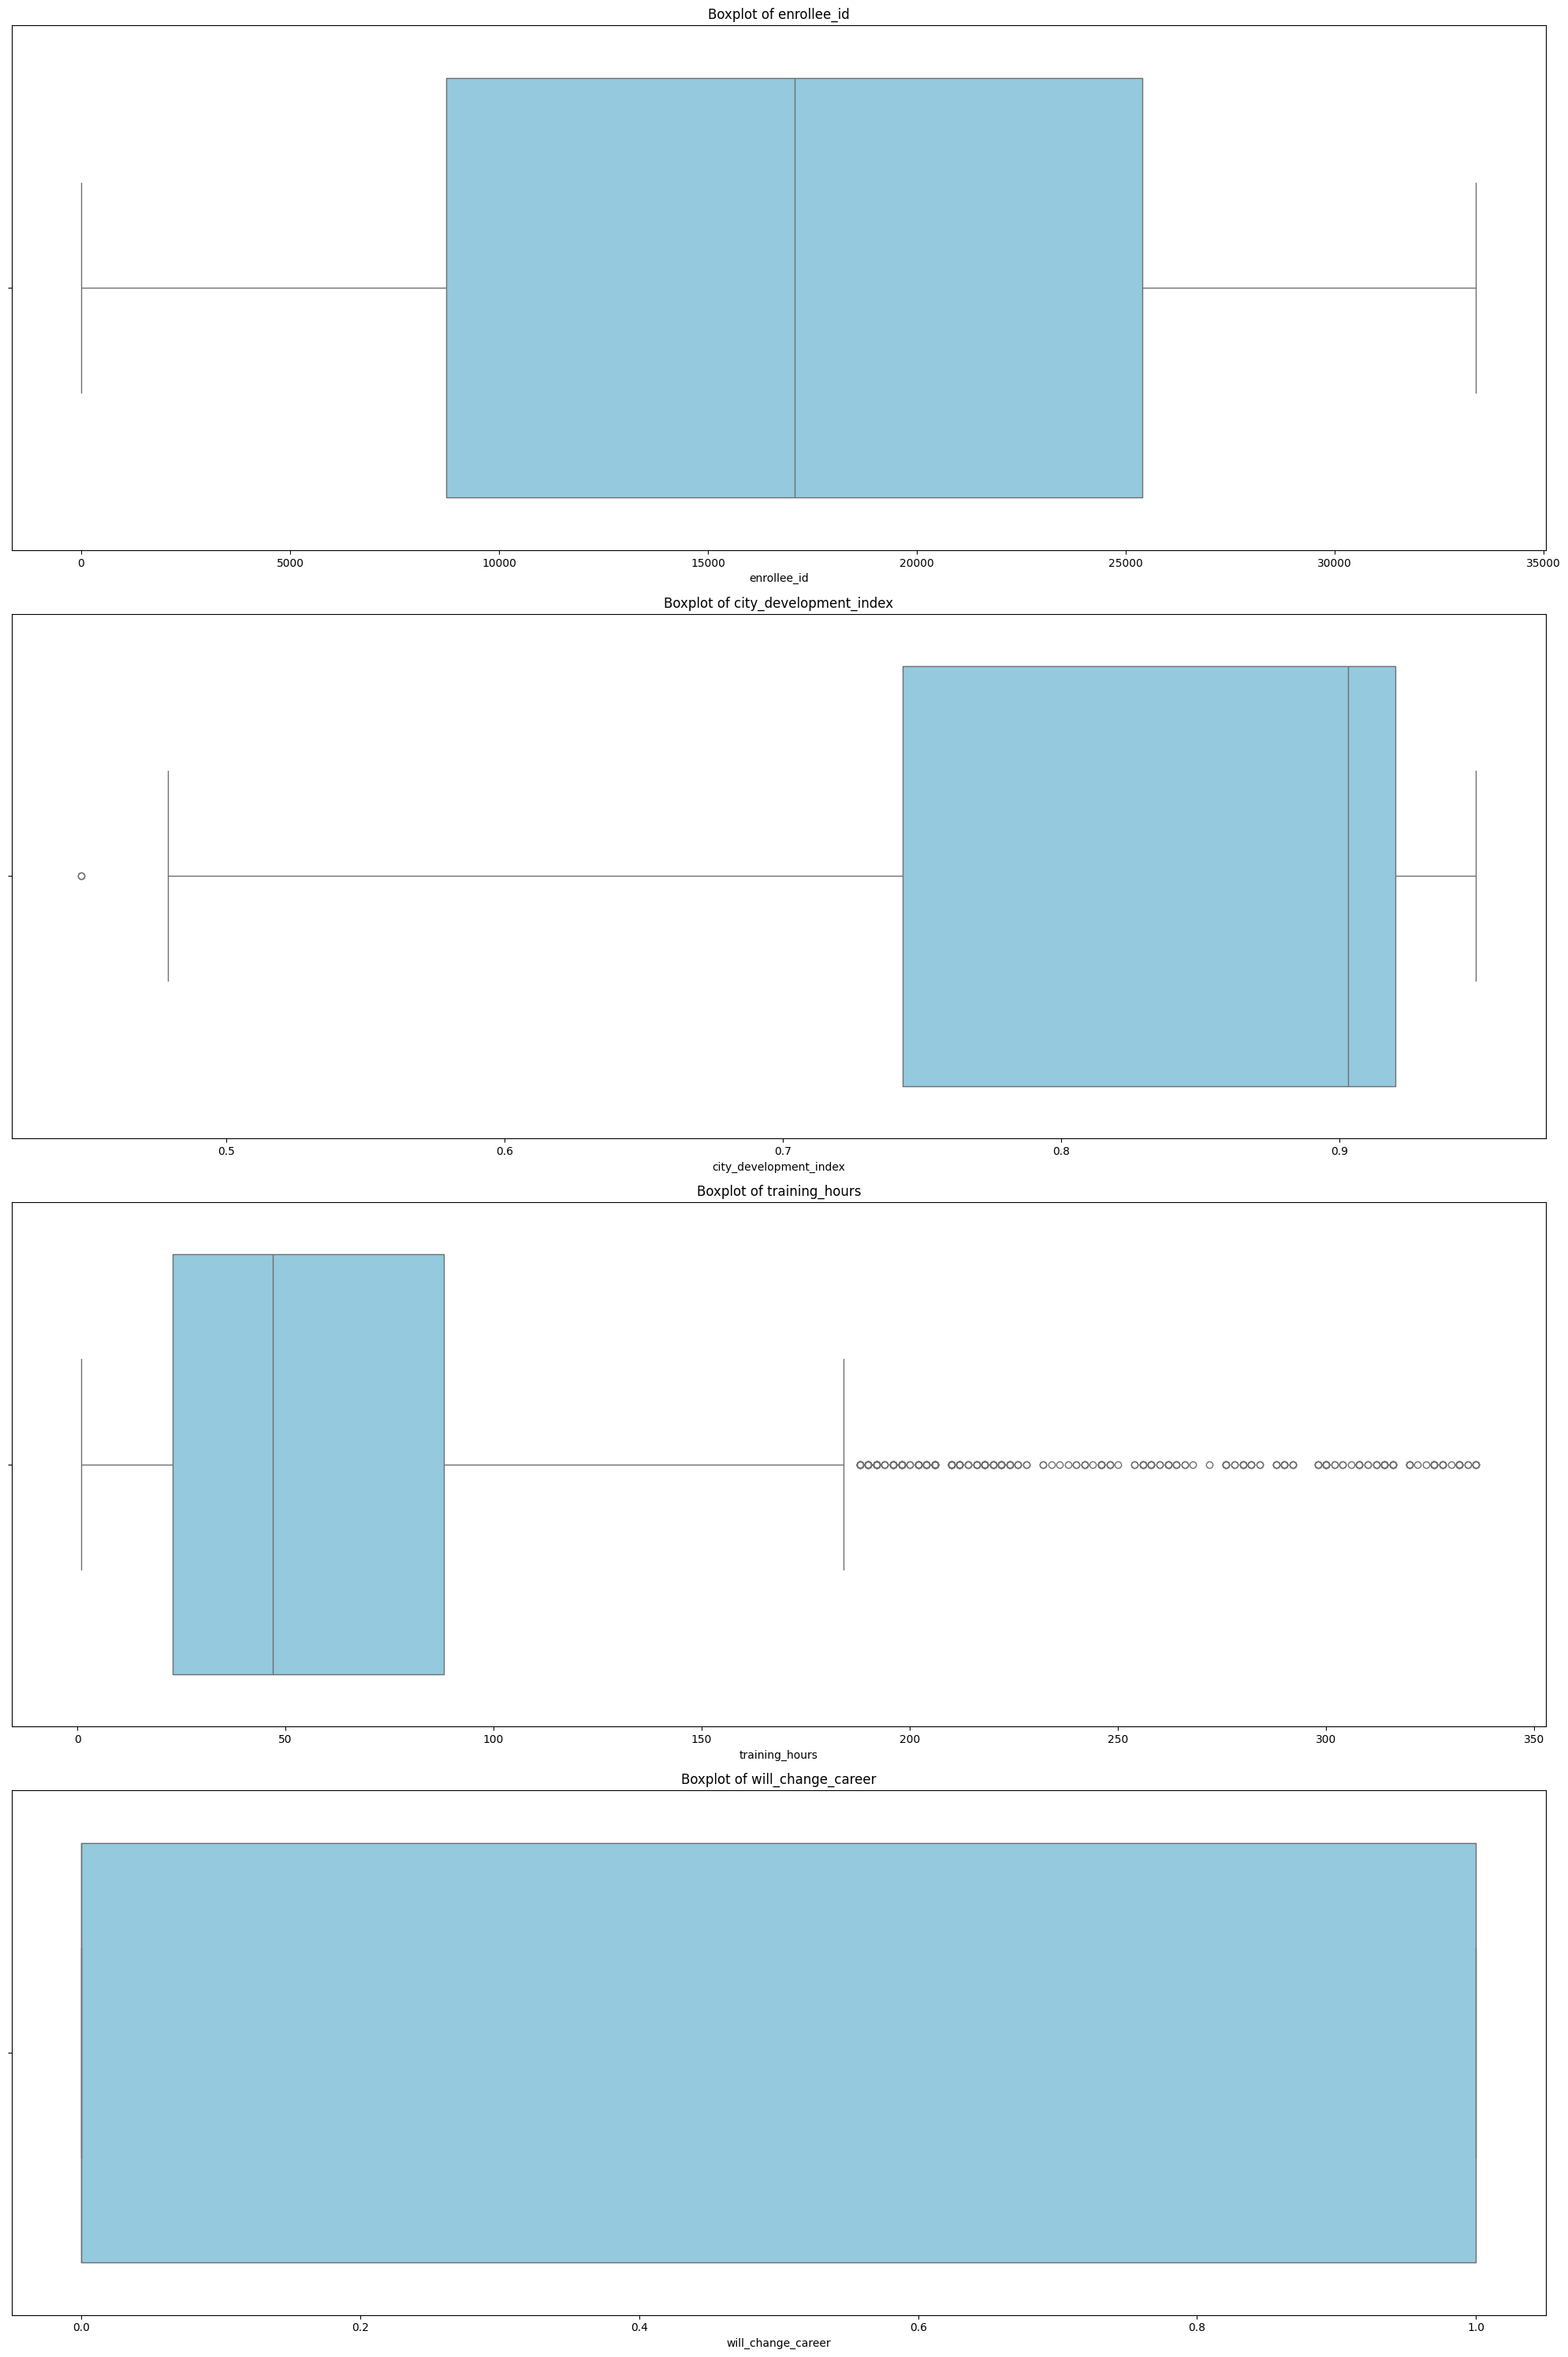

In [ ]:
numeric_cols = career.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(20, 30))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=career[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
numerical_data.nunique()

,0
enrollee_id,5000
city_development_index,85
training_hours,238
will_change_career,2


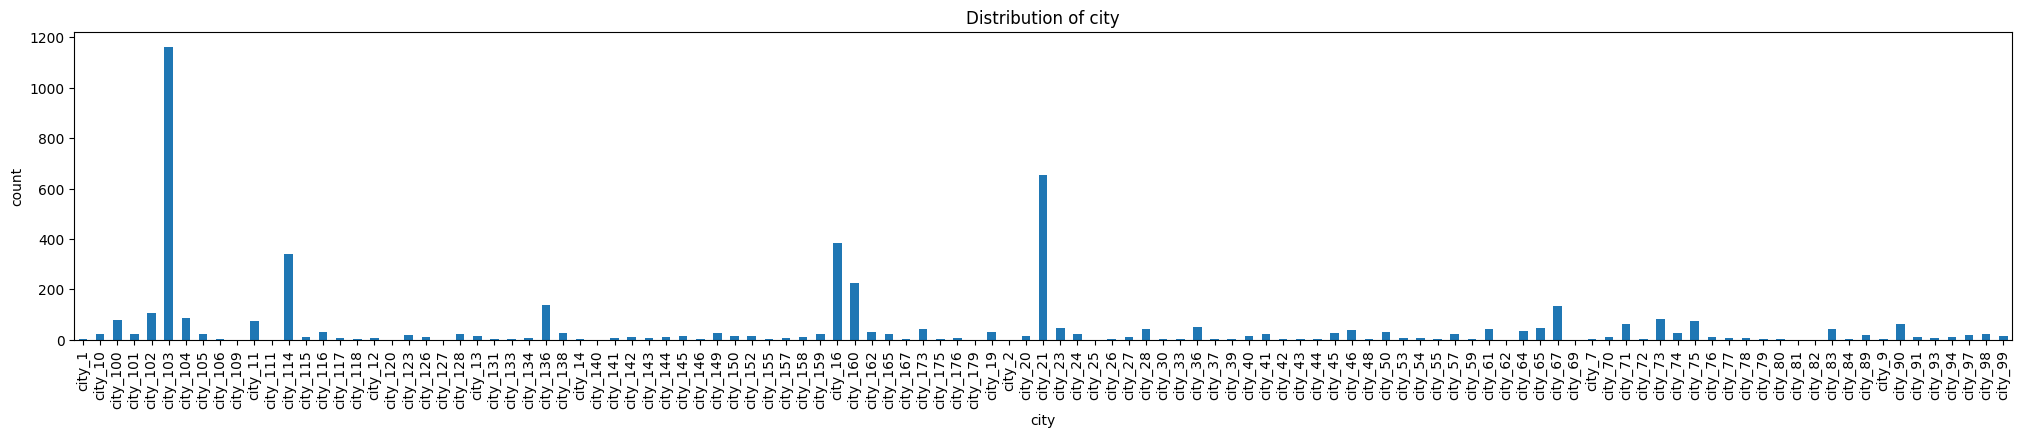

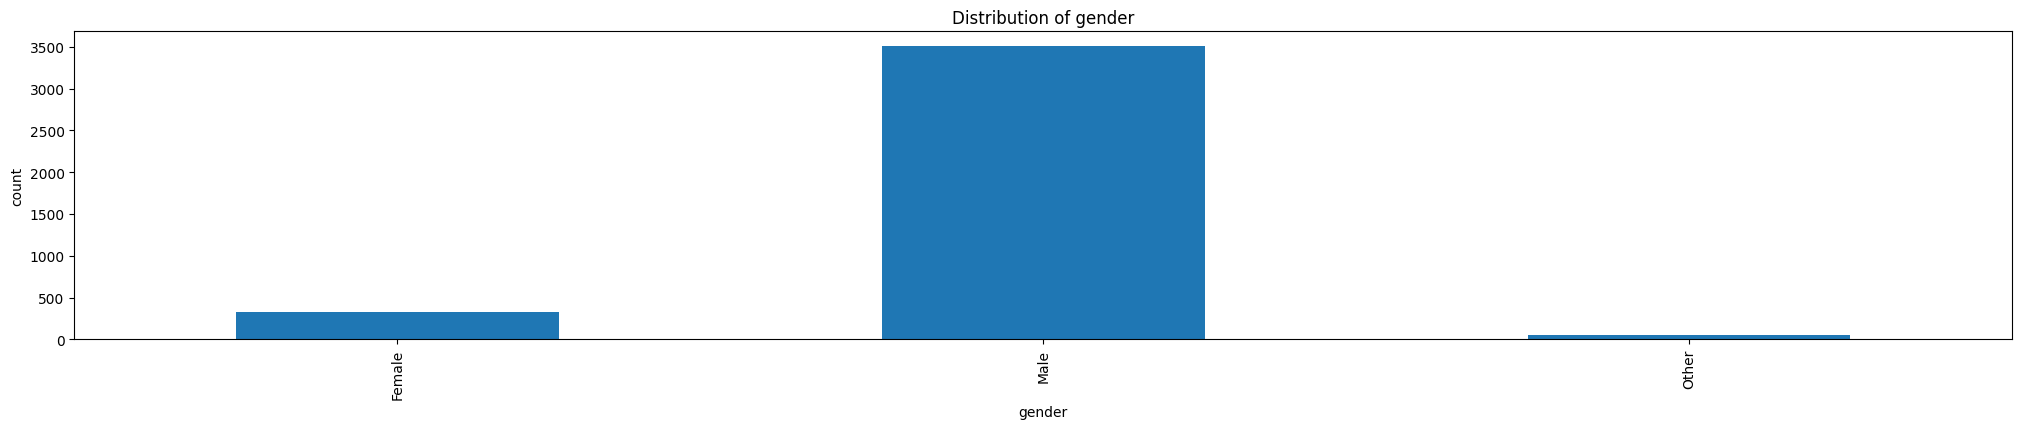

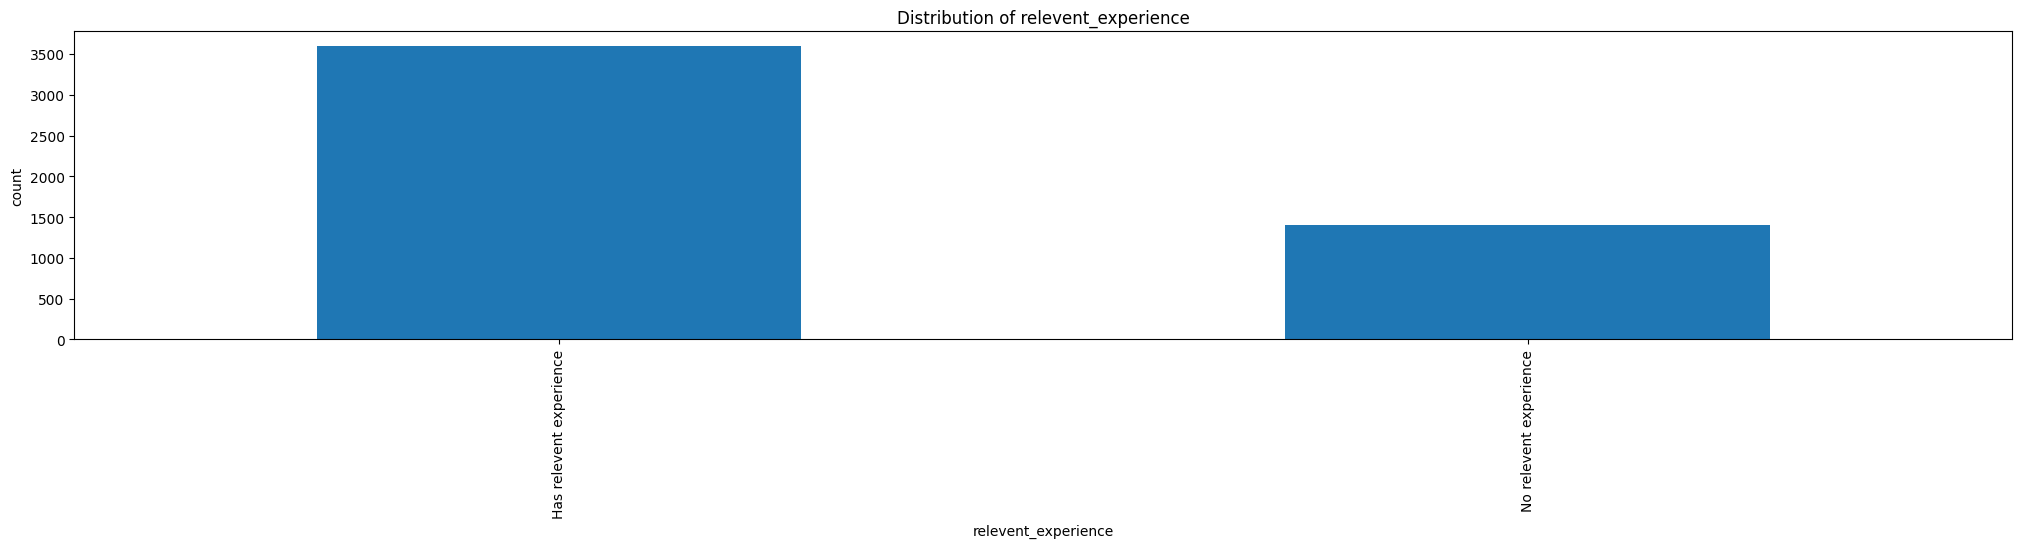

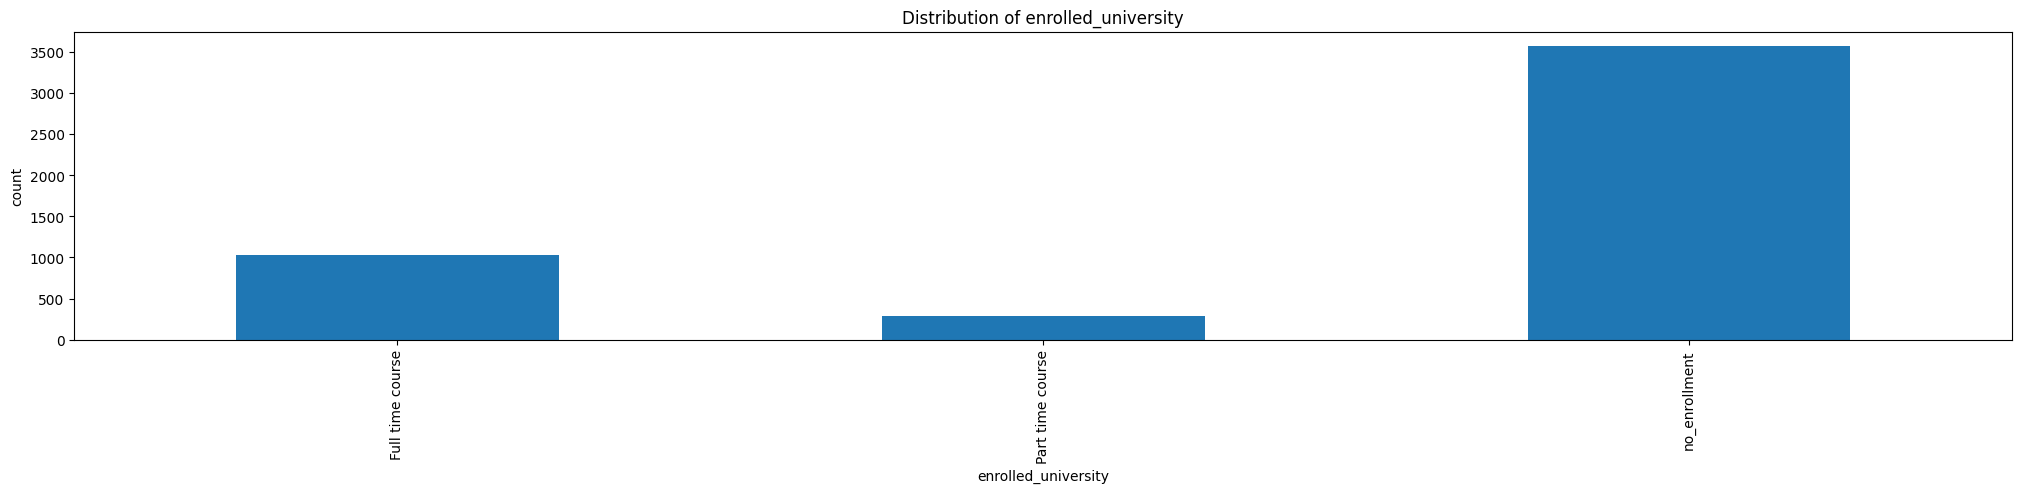

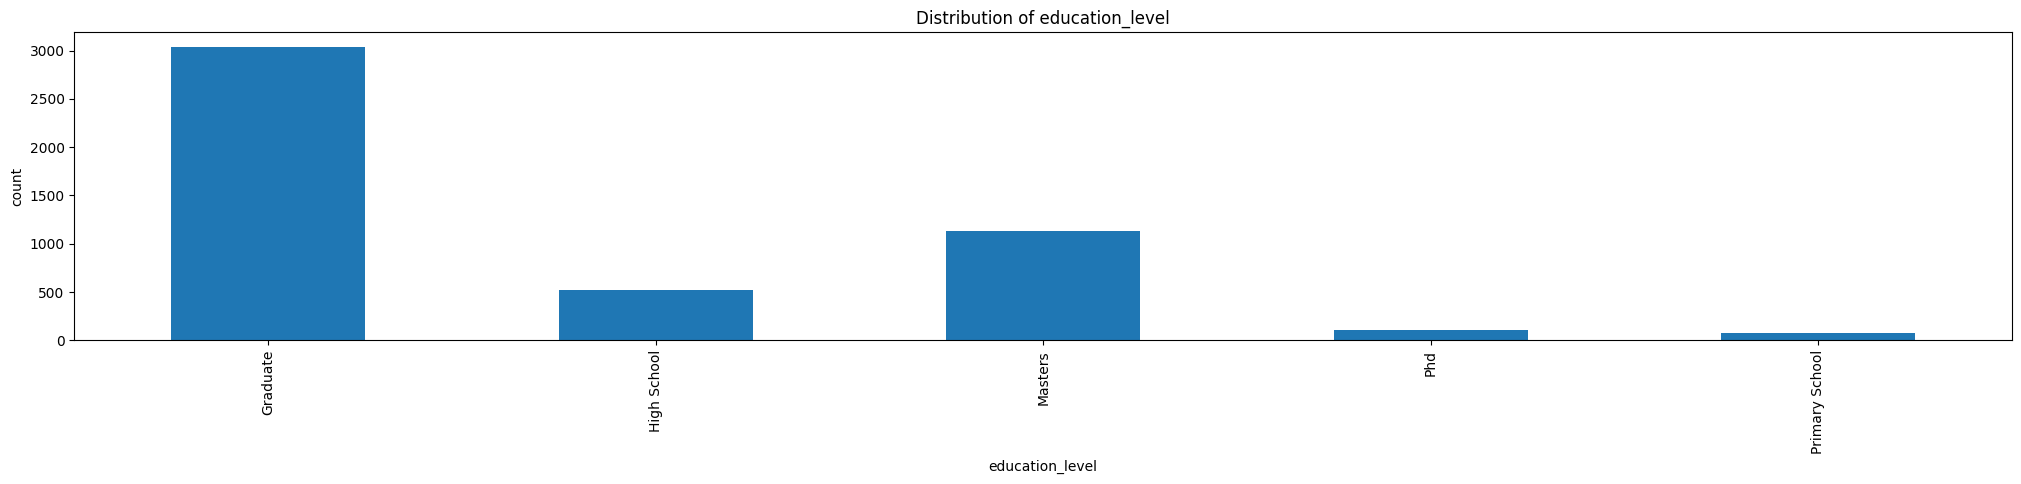

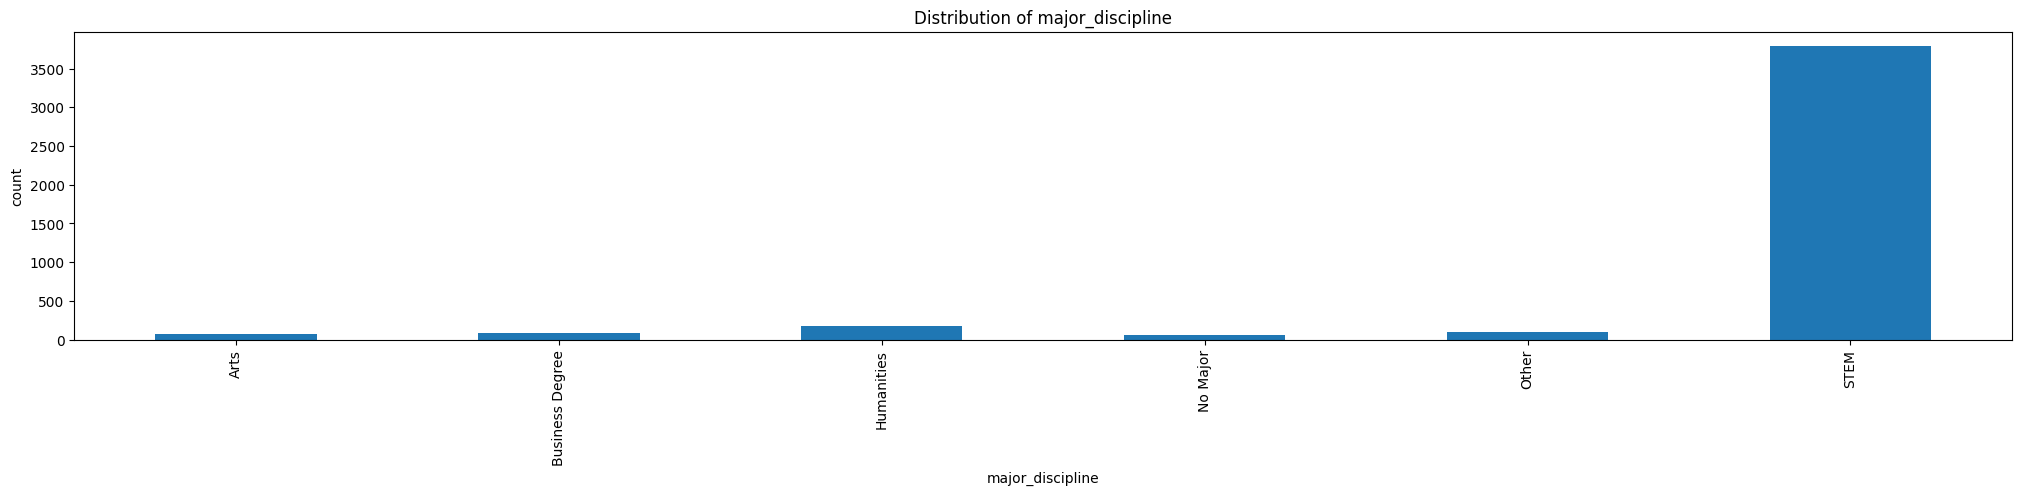

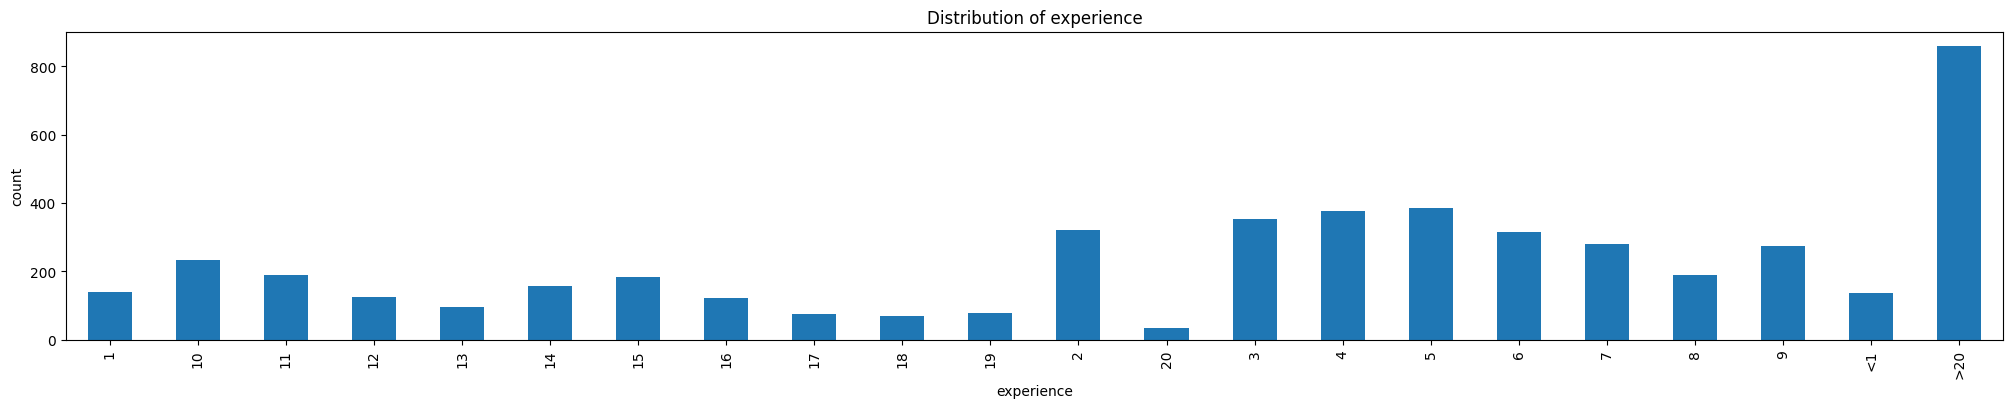

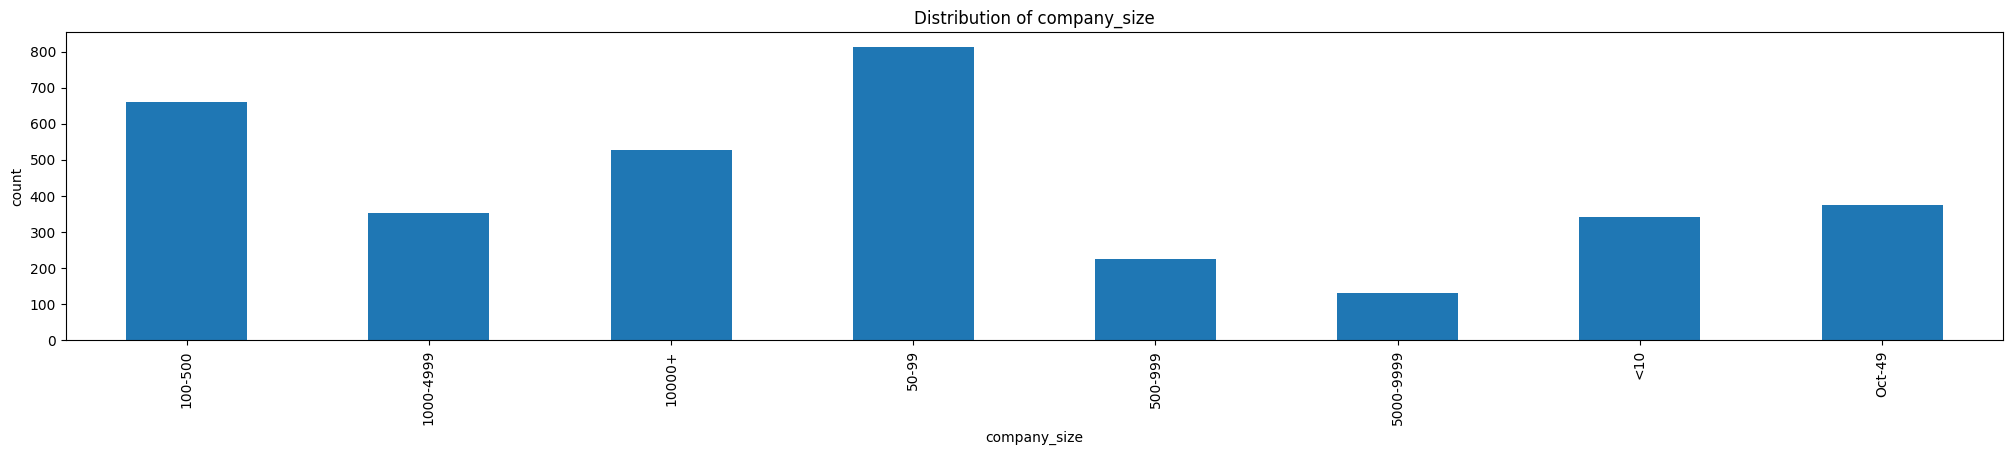

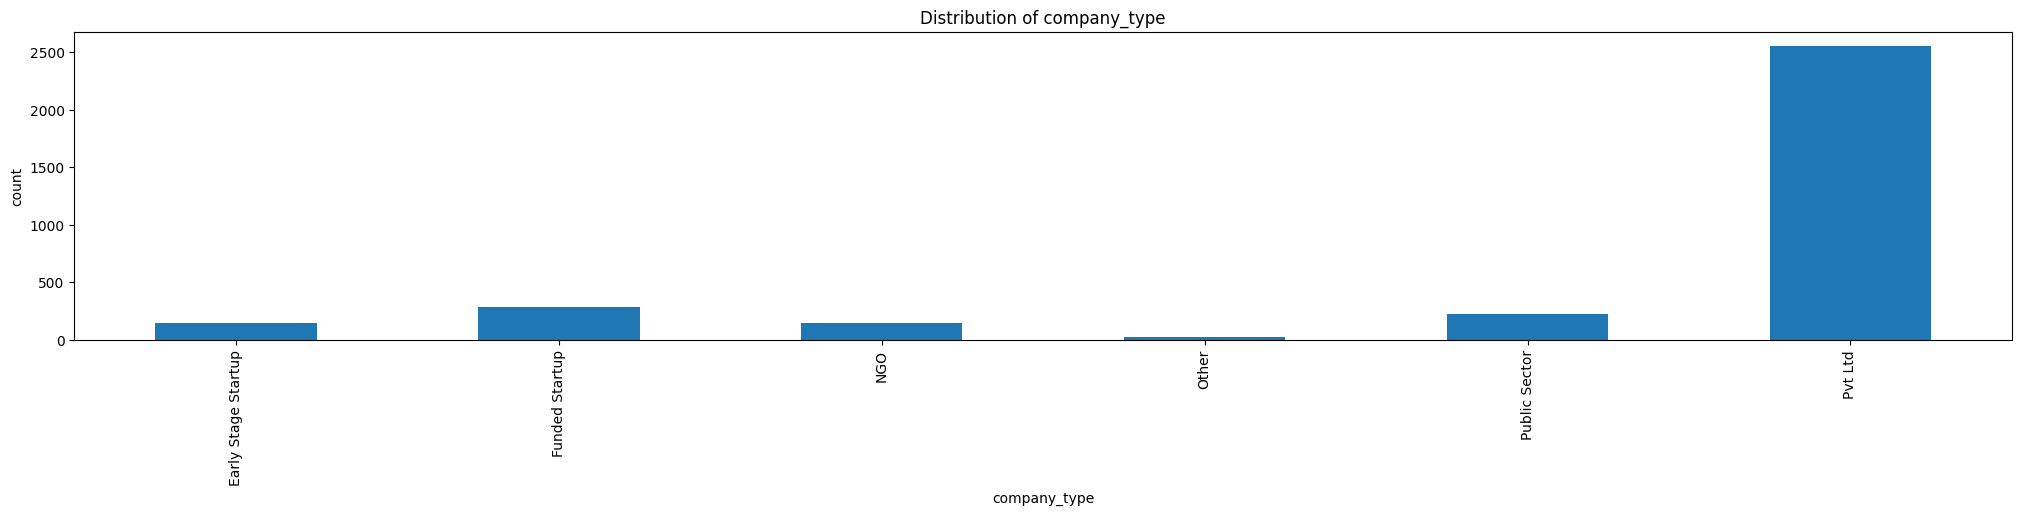

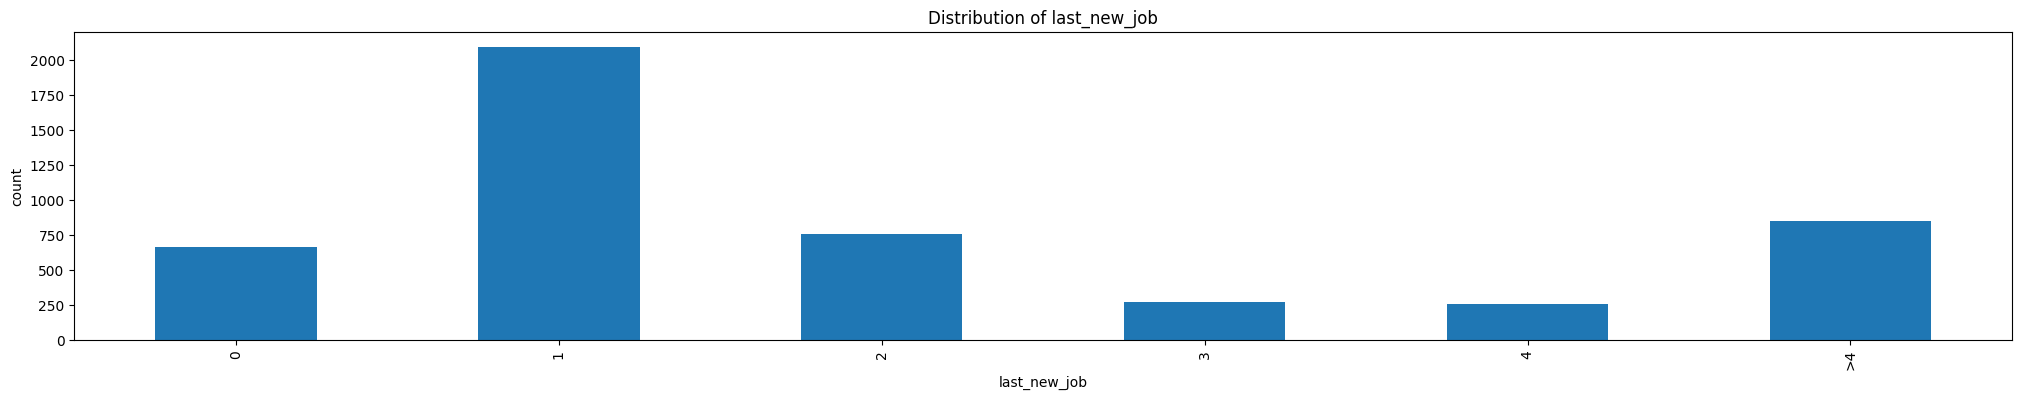

In [ ]:
for col in categorical_features:
    plt.figure(figsize=(25, 4))
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=90, xlabel=col,ylabel='count')
    plt.show()

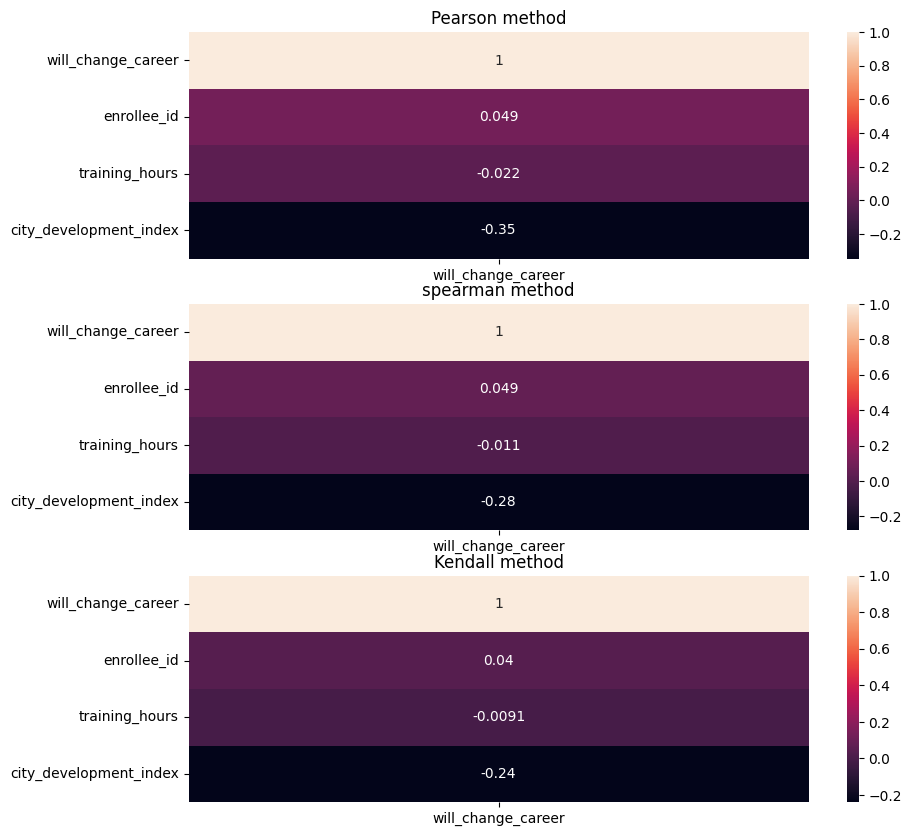

In [ ]:
fig, ax = plt.subplots(3,1, figsize=(10, 10))
## Correlation coefficient using different methods
corr1 = numerical_data.corr('pearson')[['will_change_career']].sort_values(by='will_change_career', ascending=False)
corr2 = numerical_data.corr('spearman')[['will_change_career']].sort_values(by='will_change_career', ascending=False)
corr3 = numerical_data.corr('kendall')[['will_change_career']].sort_values(by='will_change_career', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

#check Imbalance in data


In [ ]:
class_counts=career.groupby("will_change_career").size()

columns=['outcome','count','percentage']
outcome=[0,1]
count=list()
percentage=list()


for val in range(2):
    count.append(class_counts[val])
    percent=(class_counts[val]/5000)*100
    percentage.append(percent)


imbalance_df=pd.DataFrame(list(zip(outcome,count,percentage)),columns=columns)
imbalance_df



,outcome,count,percentage
0,0,3738,74.76
1,1,1262,25.24


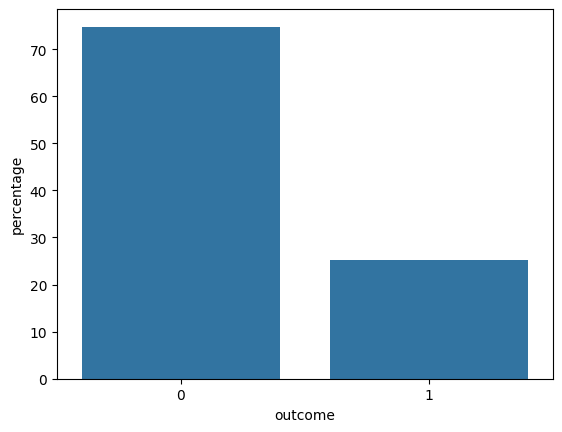

In [ ]:
sns.barplot(data=imbalance_df,x=imbalance_df['outcome'],y=imbalance_df['percentage'])
plt.show()

Observation

* Based on the above grouping, It shows that around 74.76% of instances consists OUTCOME value '0' and 25.24% of instances consists OUTCOME values '1'

* There is imbalance between two classes (approx 49.52% difference)

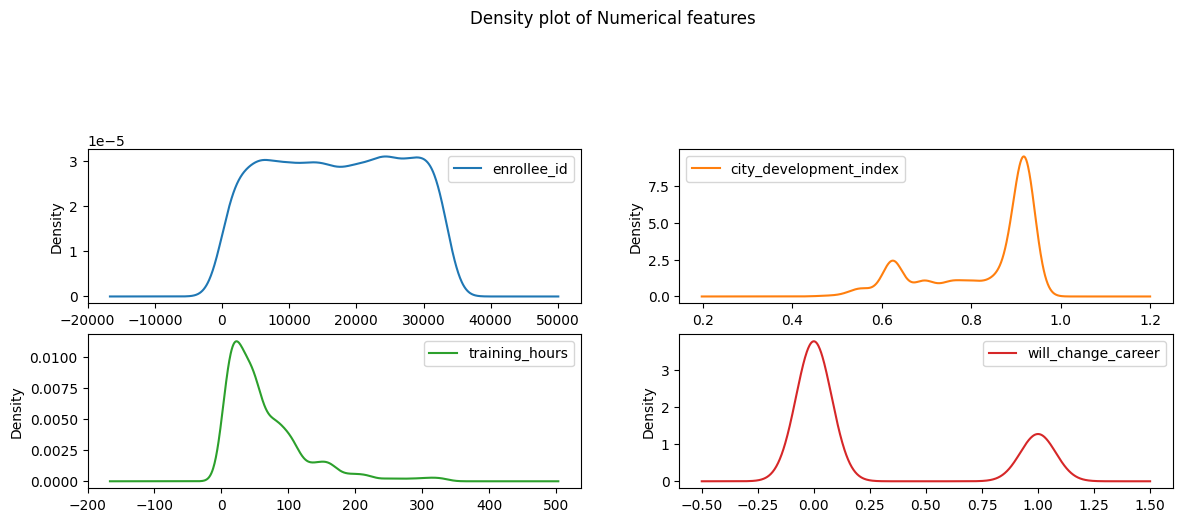

In [ ]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot of Numerical features",sharex=False)
plt.show()

DATA PRE-PROCESSING


In [ ]:
career.isnull().sum()

,0
enrollee_id,0
city,0
city_development_index,0
gender,1113
relevent_experience,0
enrolled_university,107
education_level,118
major_discipline,724
experience,11
company_size,1571


In [ ]:
num_col = ['city_development_index', 'training_hours']
for col in num_col:
    career[col].fillna(career[col].median(), inplace=True)

category_col = ['enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']
for col in category_col:
    career[col].fillna(career[col].mode()[0], inplace=True)

career['gender'].fillna('Female', inplace=True)

/tmp/ipython-input-1177035761.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  career[col].fillna(career[col].median(), inplace=True)
/tmp/ipython-input-1177035761.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

In [ ]:
career.isnull().sum()

,0
enrollee_id,0
city,0
city_development_index,0
gender,0
relevent_experience,0
enrolled_university,0
education_level,0
major_discipline,0
experience,0
company_size,0


In [ ]:
career.head(15)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,will_change_career
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1,36,1
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,11561,city_21,0.624,Female,No relevent experience,Full time course,Graduate,STEM,5,50-99,Pvt Ltd,0,83,0
3,33241,city_115,0.789,Female,No relevent experience,no_enrollment,Graduate,Business Degree,<1,50-99,Pvt Ltd,0,52,1
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0
5,21651,city_176,0.764,Female,Has relevent experience,Part time course,Graduate,STEM,11,50-99,Pvt Ltd,1,24,1
6,28806,city_160,0.920,Male,Has relevent experience,no_enrollment,High School,STEM,5,50-99,Funded Startup,1,24,0
7,402,city_46,0.762,Male,Has relevent experience,no_enrollment,Graduate,STEM,13,<10,Pvt Ltd,>4,18,1
8,27107,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,46,1
9,699,city_103,0.920,Female,Has relevent experience,no_enrollment,Graduate,STEM,17,10000+,Pvt Ltd,>4,123,0


ENCODING

In [ ]:
from sklearn.preprocessing import LabelEncoder

career_encoded = career.copy()

label_enc = LabelEncoder()

binary_ordinal_cols = ['relevent_experience', 'education_level', 'company_size','last_new_job']

for col in binary_ordinal_cols:
    career_encoded[col] = career_encoded[col].astype(str)
    career_encoded[col] = label_enc.fit_transform(career_encoded[col])

experience_map = {'<1': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, '10': 10,'11': 11, '12': 12, '13': 13, '14': 14, '15': 15,'16': 16, '17': 17, '18': 18, '19': 19, '20': 20, '>20': 21}

career_encoded['experience'] = career_encoded['experience'].map(experience_map)

onehot_cols = ['gender', 'enrolled_university', 'major_discipline', 'company_type']
career_encoded = pd.get_dummies(career_encoded, columns=onehot_cols, drop_first=True)

city_target_mean = career_encoded.groupby('city')['will_change_career'].mean()
career_encoded['city'] = career_encoded['city'].map(city_target_mean)

print("Encoding complete! Here's the shape of encoded dataset:")
print(career_encoded.shape)
career_encoded.head()


Encoding complete! Here's the shape of encoded dataset:
(5000, 24)


,enrollee_id,city,city_development_index,relevent_experience,education_level,experience,company_size,last_new_job,training_hours,will_change_career,...,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd
0,8949,0.216681,0.920,0,0,21,3,1,36,1,...,False,False,False,False,True,False,False,False,False,True
1,29725,0.071429,0.776,1,0,15,3,5,47,0,...,False,False,False,False,True,False,False,False,False,True
2,11561,0.613740,0.624,1,0,5,3,0,83,0,...,False,False,False,False,True,False,False,False,False,True
3,33241,0.538462,0.789,1,0,0,3,0,52,1,...,True,False,False,False,False,False,False,False,False,True
4,666,0.366667,0.767,0,2,21,3,4,8,0,...,False,False,False,False,True,True,False,False,False,False


In [ ]:
# List of one-hot encoded columns
one_hot_columns = [
    'major_discipline_Business Degree', 'major_discipline_Humanities',
    'major_discipline_No Major', 'major_discipline_Other', 'major_discipline_STEM',
    'company_type_Funded Startup', 'company_type_NGO',
    'company_type_Other', 'company_type_Public Sector', 'company_type_Pvt Ltd'
]

# Convert True/False to 1/0
career_encoded[one_hot_columns] = career_encoded[one_hot_columns].astype(int)
career_encoded.head()

,enrollee_id,city,city_development_index,relevent_experience,education_level,experience,company_size,last_new_job,training_hours,will_change_career,...,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd
0,8949,0.216681,0.920,0,0,21,3,1,36,1,...,0,0,0,0,1,0,0,0,0,1
1,29725,0.071429,0.776,1,0,15,3,5,47,0,...,0,0,0,0,1,0,0,0,0,1
2,11561,0.613740,0.624,1,0,5,3,0,83,0,...,0,0,0,0,1,0,0,0,0,1
3,33241,0.538462,0.789,1,0,0,3,0,52,1,...,1,0,0,0,0,0,0,0,0,1
4,666,0.366667,0.767,0,2,21,3,4,8,0,...,0,0,0,0,1,1,0,0,0,0


In [ ]:
career_encoded.drop(columns=['enrollee_id'], inplace=True)


In [ ]:
career_encoded.head()

,city,city_development_index,relevent_experience,education_level,experience,company_size,last_new_job,training_hours,will_change_career,gender_Male,...,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd
0,0.216681,0.920,0,0,21,3,1,36,1,True,...,0,0,0,0,1,0,0,0,0,1
1,0.071429,0.776,1,0,15,3,5,47,0,True,...,0,0,0,0,1,0,0,0,0,1
2,0.613740,0.624,1,0,5,3,0,83,0,False,...,0,0,0,0,1,0,0,0,0,1
3,0.538462,0.789,1,0,0,3,0,52,1,False,...,1,0,0,0,0,0,0,0,0,1
4,0.366667,0.767,0,2,21,3,4,8,0,True,...,0,0,0,0,1,1,0,0,0,0


SCALING

In [ ]:
X = career_encoded.drop(columns=['will_change_career'])
y = career_encoded['will_change_career']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

TRAIN TEST

In [ ]:
# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=40, stratify=y)


STRATIFY - HYBRID(SAMPLING)

In [ ]:
smote_enn = SMOTEENN(random_state=42)
X_smenn, y_smenn = smote_enn.fit_resample(X_train, y_train)
print("After SMOTEENN:", Counter(y_smenn))

After SMOTEENN: Counter({1: 1854, 0: 1320})


In [ ]:
models = {
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000)}

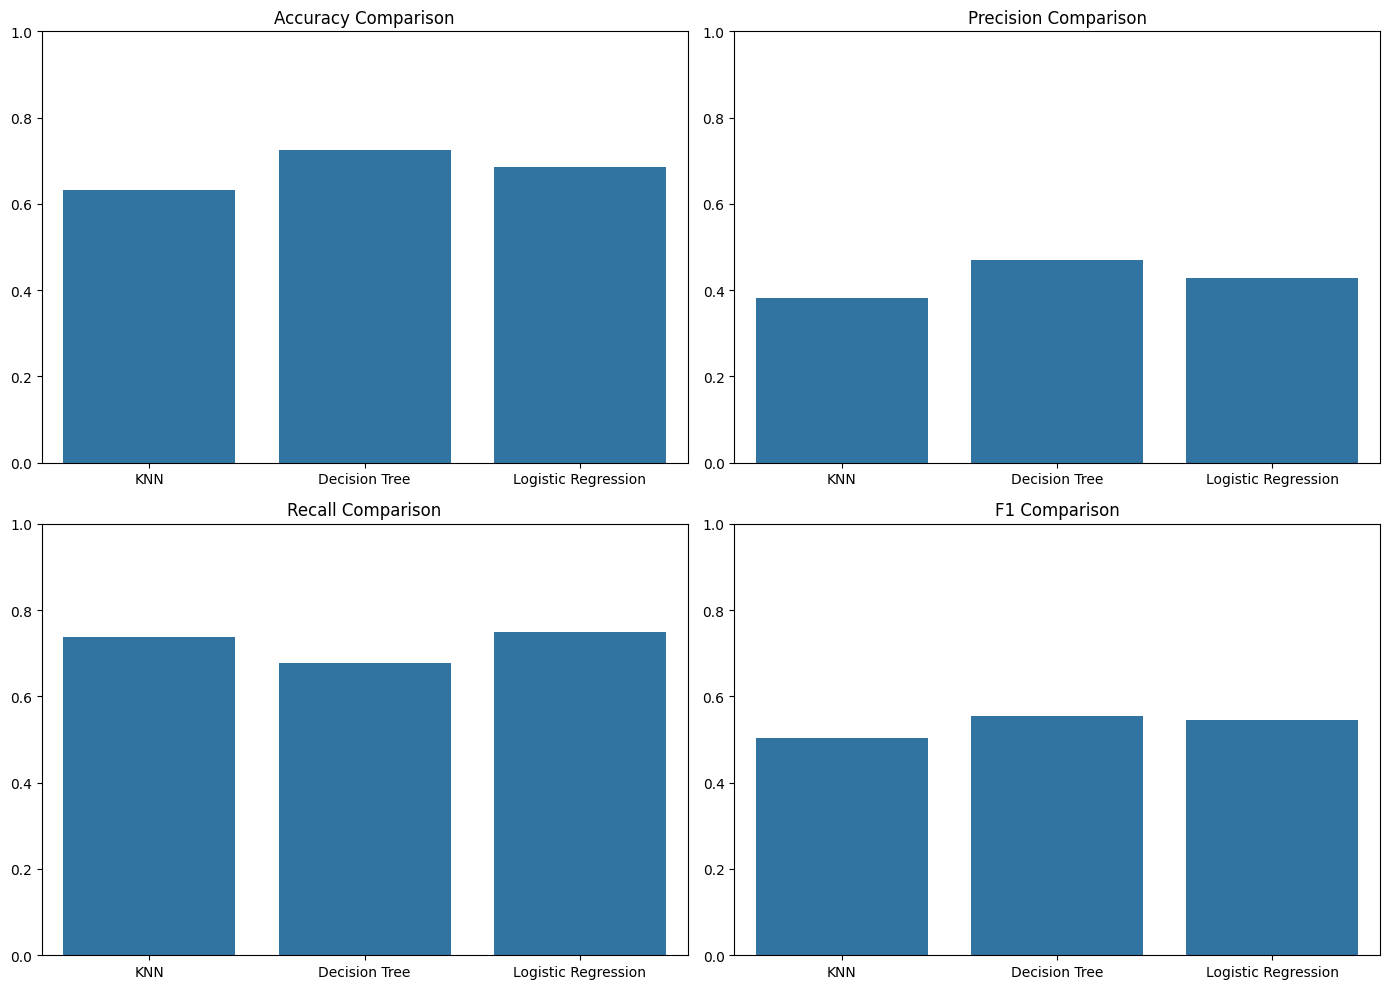

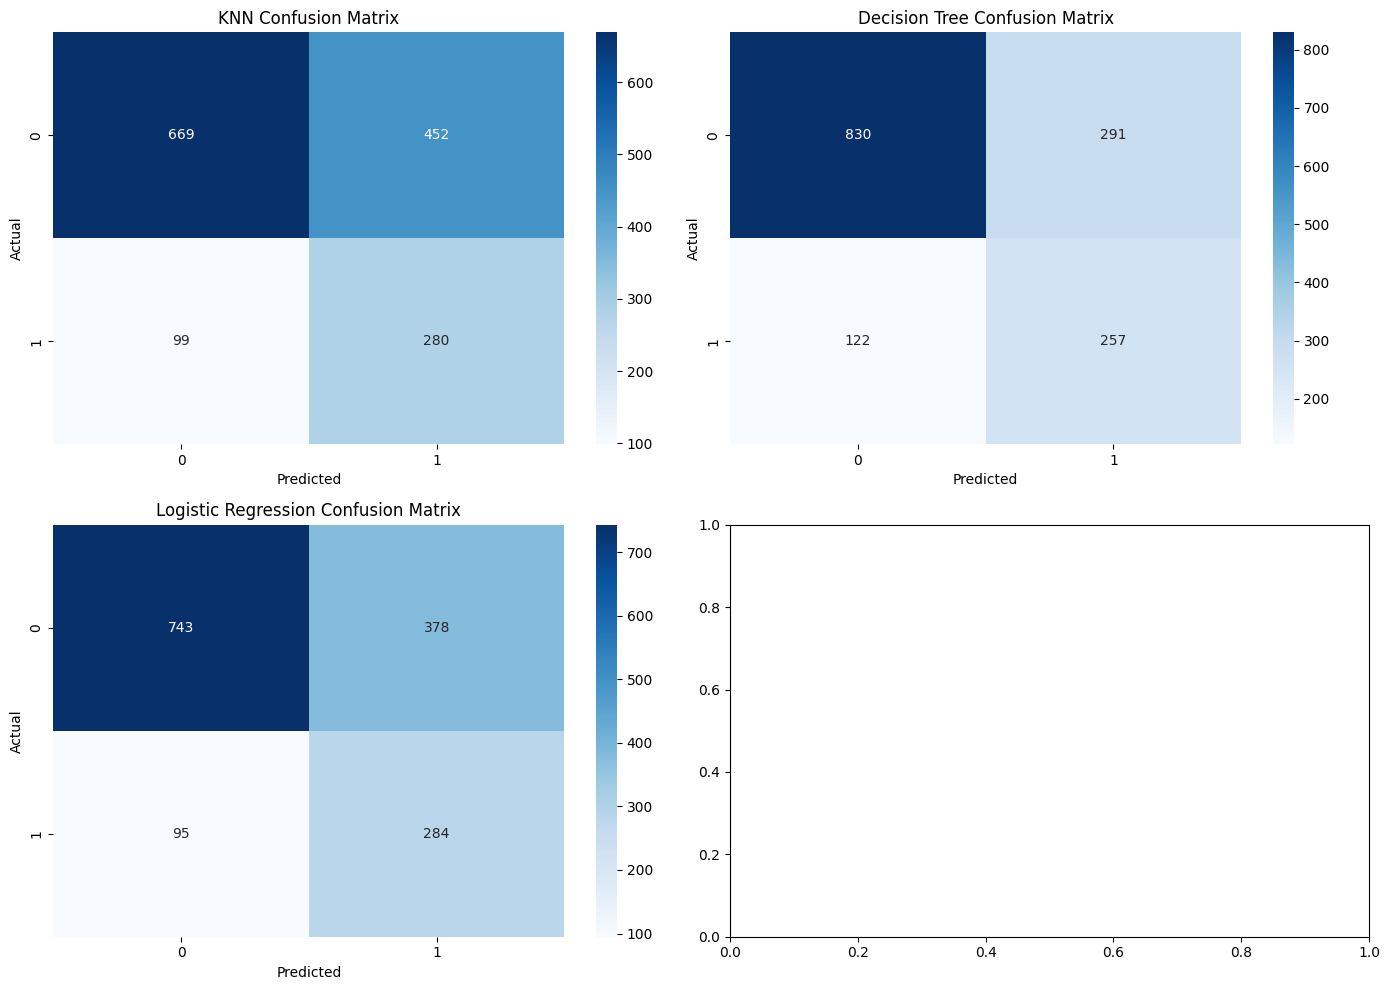

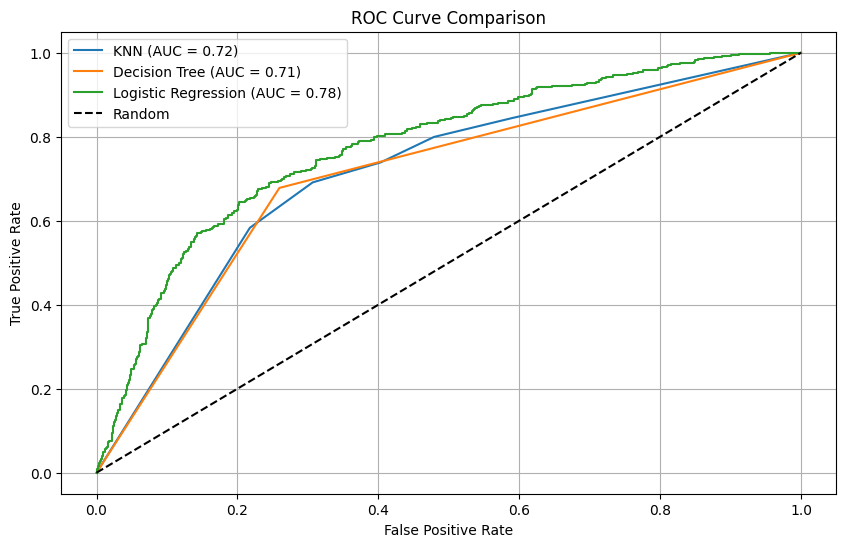

In [ ]:

results = {
    'Model': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1': [],
    'AUC': [],
    'FPR': [],
    'TPR': [],
    'ConfusionMatrix': []
}

for name, model in models.items():
    model.fit(X_smenn, y_smenn)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None


    results['Model'].append(name)
    results['Accuracy'].append(accuracy_score(y_test, y_pred))
    results['Precision'].append(precision_score(y_test, y_pred))
    results['Recall'].append(recall_score(y_test, y_pred))
    results['F1'].append(f1_score(y_test, y_pred))
    results['ConfusionMatrix'].append(confusion_matrix(y_test, y_pred))

    # ROC AUC
    if y_proba is not None:
        auc = roc_auc_score(y_test, y_proba)
        fpr, tpr, _ = roc_curve(y_test, y_proba)
    else:
        auc, fpr, tpr = None, None, None

    results['AUC'].append(auc)
    results['FPR'].append(fpr)
    results['TPR'].append(tpr)

# 1. Accuracy, Precision, Recall, F1
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()
for idx, metric in enumerate(metrics):
    sns.barplot(x=results['Model'], y=results[metric], ax=axes[idx])
    axes[idx].set_title(f'{metric} Comparison')
    axes[idx].set_ylim(0, 1)
plt.tight_layout()
plt.show()

# 2. Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()
for idx, cm in enumerate(results['ConfusionMatrix']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx])
    axes[idx].set_title(f'{results["Model"][idx]} Confusion Matrix')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
plt.tight_layout()
plt.show()

# 3. ROC Curves
plt.figure(figsize=(10, 6))
for i in range(len(results['Model'])):
    if results['FPR'][i] is not None:
        plt.plot(results['FPR'][i], results['TPR'][i], label=f"{results['Model'][i]} (AUC = {results['AUC'][i]:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()


In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(22,)),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=Adam(0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model. fit(X_train, y_train, epochs = 30, batch_size=128)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7332 - loss: 0.5846
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7882 - loss: 0.4861
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7846 - loss: 0.4740
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7919 - loss: 0.4486
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8048 - loss: 0.4384 
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7848 - loss: 0.4652 
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7963 - loss: 0.4402 
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8044 - loss: 0.4302
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8059 - loss: 0.4329 
Epoch 10/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8082 - loss: 0.4162 
Epoch 11/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7999 - loss: 0.4271 
Epoch 12/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.806

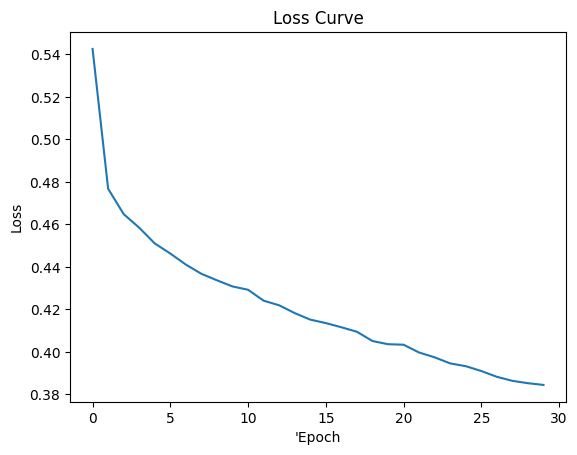

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7745 - loss: 0.4988
Testing Accuracy: 76.73%


In [ ]:
# Plot loss curve
plt.plot(history.history['loss'])
plt.title("Loss Curve")
plt.xlabel("'Epoch")
plt. ylabel("Loss")
plt.show()
print(f"Testing Accuracy: {round(model.evaluate(X_test, y_test)[1] * 100, 2)}%")